# Resumen de Resultados: Representaciones Políticas Lineales
Este notebook consolida los análisis y visualizaciones de los experimentos de la tesis, cubriendo descubrimiento de ideología, steering causal y análisis cross-cultural.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from pathlib import Path
from IPython.display import Image, display

# Configuración visual
sns.set_theme(style="whitegrid")

# Rutas
BASE_DIR = Path('.').resolve()
if BASE_DIR.name == 'notebooks':
    BASE_DIR = BASE_DIR.parent
RESULTS_DIR = BASE_DIR / 'results'
FIGURES_DIR = BASE_DIR / 'figures'



## 1. Descubrimiento de Representaciones (Probing)
Mapa de calor de la correlación de Spearman para el método de Nominate y B-Call. Muestra en qué capas y cabezas el modelo codifica la ideología de manera más fuerte.


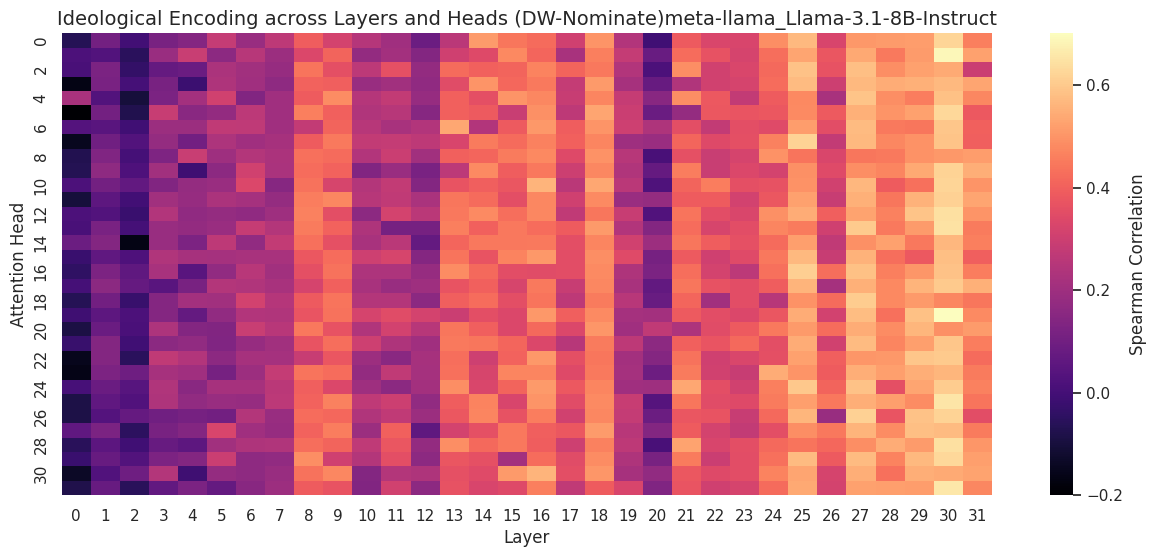

In [2]:

def plot_probing_heatmap(model_name):
    path = RESULTS_DIR / f'probing/nominate/interventions/{model_name}_politician_performance.pkl'
    if not path.exists():
        print(f"No se encontró el archivo de probing para {model_name}")
        return
    with open(path, 'rb') as f:
        perf = pickle.load(f)
        
    plt.figure(figsize=(15, 6))
    sns.heatmap(perf.T, cmap='magma', cbar_kws={'label': 'Spearman Correlation'})
    plt.title(f'Ideological Encoding across Layers and Heads (DW-Nominate){model_name}', fontsize=14)
    plt.xlabel('Layer')
    plt.ylabel('Attention Head')
    plt.show()

plot_probing_heatmap('meta-llama_Llama-3.1-8B-Instruct')



## 2. Test de Causalidad (Steering)
Evaluación de la manipulación del voto variando el hiperparámetro Alpha ($\alpha$). Se compara el comportamiento de la exactitud general y la distribución de votos para los métodos supervisados (Ridge, B-Call) y no supervisados (PCA, NMF).


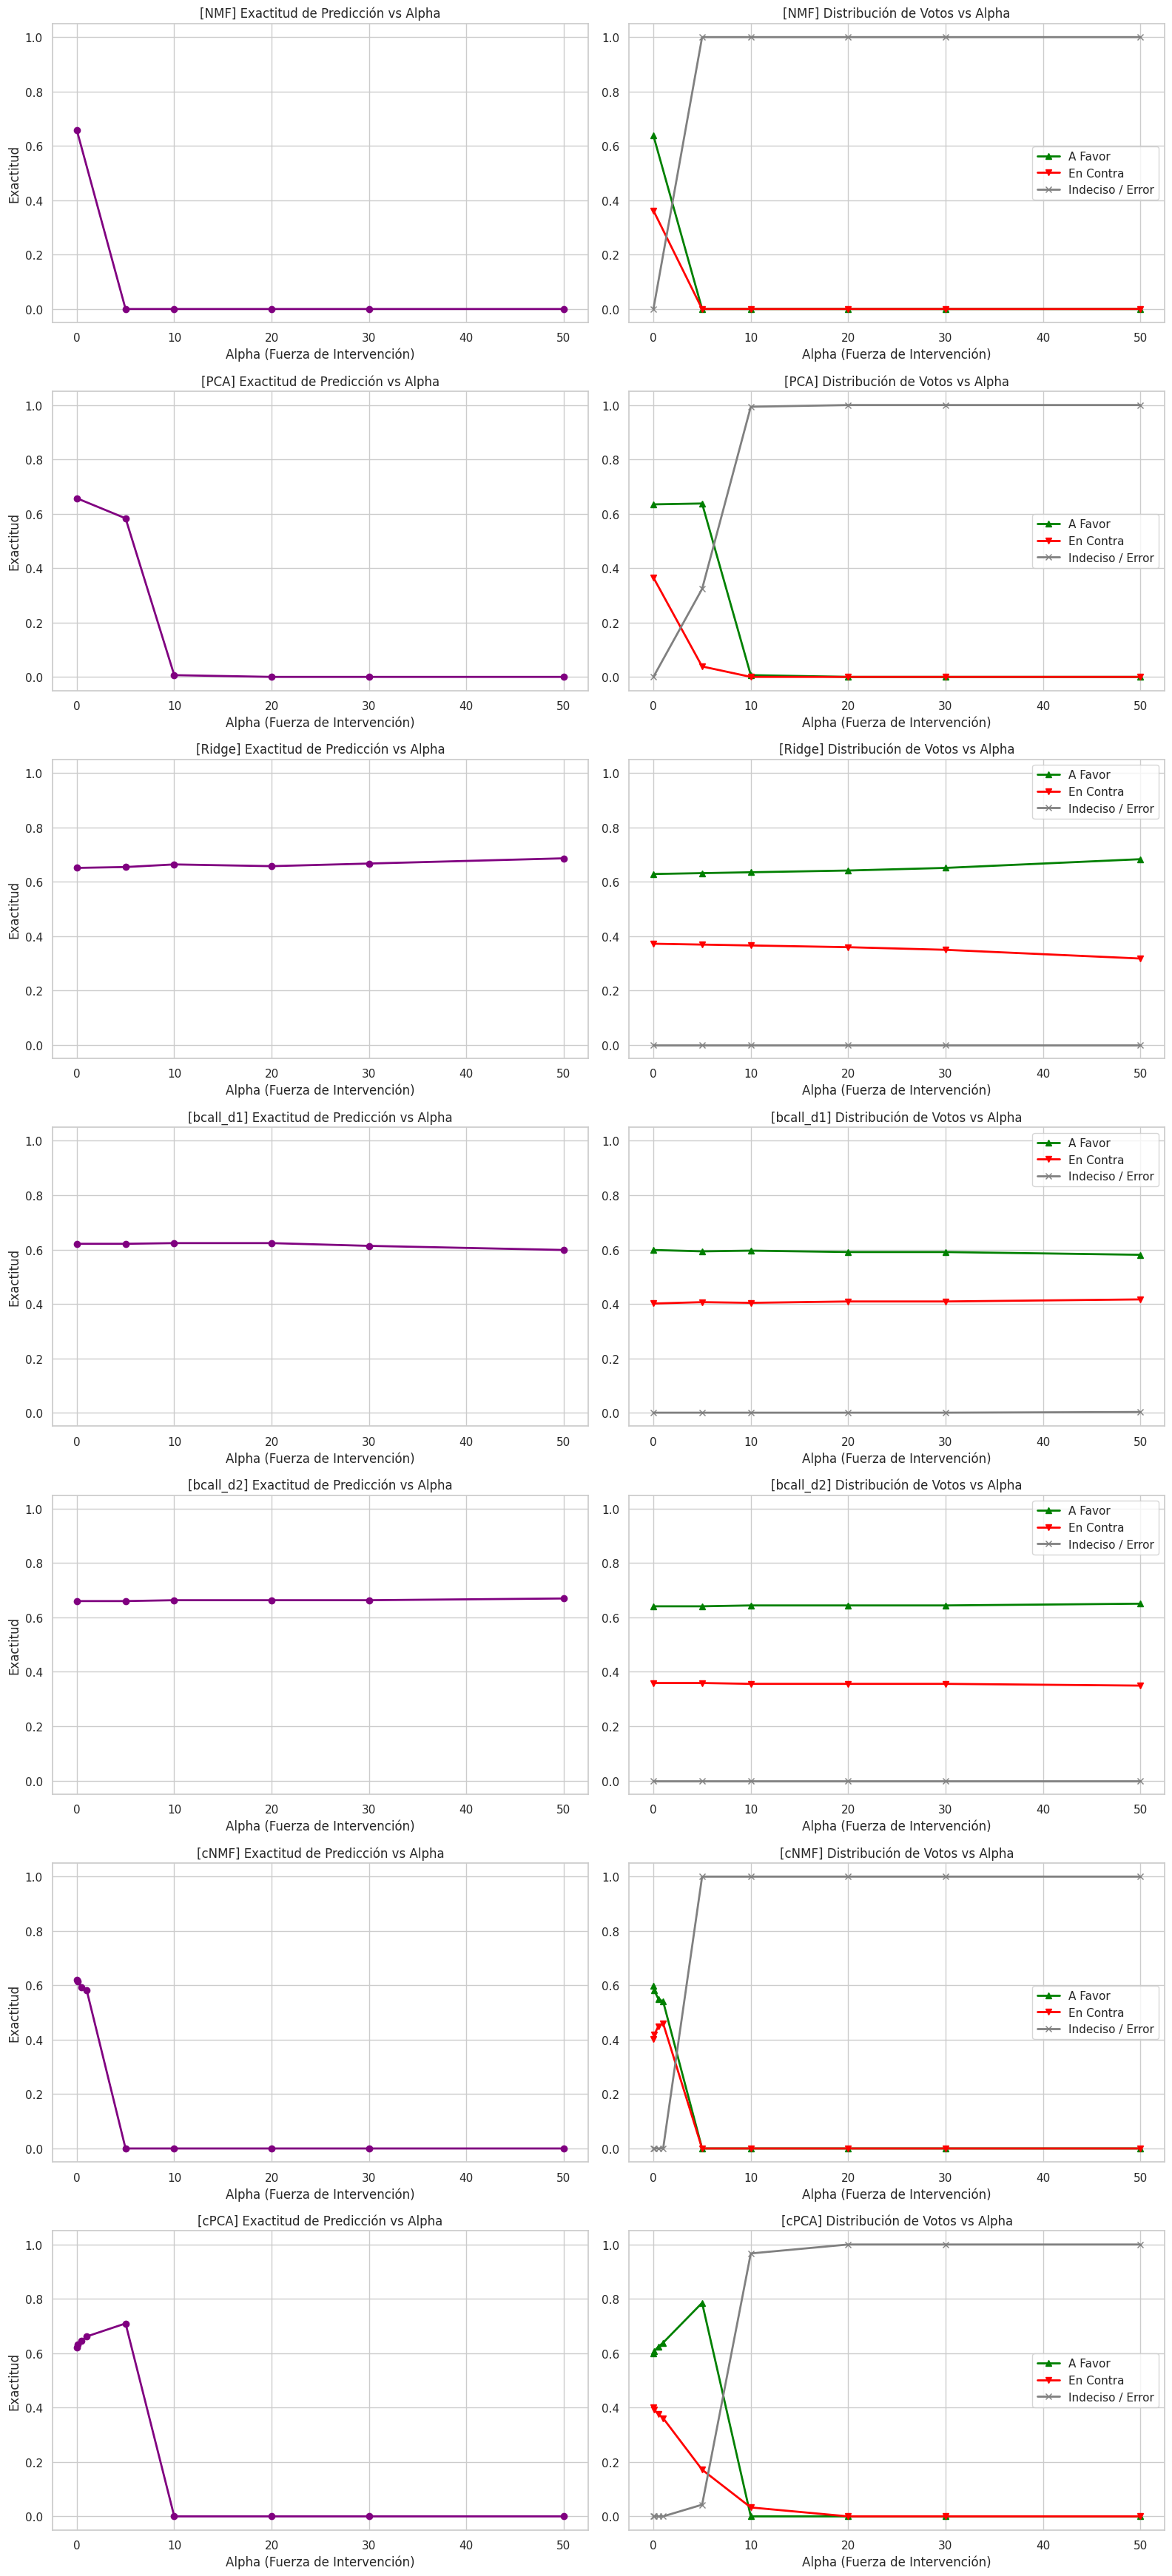

In [3]:

def analyze_steering_results(model_name):
    import glob
    files = glob.glob(str(RESULTS_DIR / f'voting_predictions/voting_predictions_{model_name}_*.parquet'))
    if not files:
        print("No hay resultados de steering para este modelo.")
        return
        
    data = []
    for f in files:
        method = f.split('_')[-1].replace('.parquet', '')
        # Un pequeño hack para que bcall_d1 se agrupe bien
        if 'bcall_d1' in f: method = 'bcall_d1'
        if 'bcall_d2' in f: method = 'bcall_d2'
        if 'pca' in f and 'cpca' not in f: method = 'PCA'
        if 'cpca' in f: method = 'cPCA'
        if 'nmf' in f and 'cnmf' not in f: method = 'NMF'
        if 'cnmf' in f: method = 'cNMF'
        if 'ridge' in f: method = 'Ridge'
        
        df = pd.read_parquet(f)
        for alpha in df['alpha'].unique():
            sub = df[df['alpha'] == alpha]
            acc = sub['acierto'].mean()
            
            counts = sub['voto_predicho'].value_counts()
            a_favor = counts.get('A FAVOR', 0) / len(sub)
            en_contra = counts.get('EN CONTRA', 0) / len(sub)
            indeciso = counts.get('INDECISO', 0) / len(sub)
            
            data.append({
                'Método': method,
                'Alpha': alpha,
                'Exactitud': acc,
                '% A Favor': a_favor,
                '% En Contra': en_contra,
                '% Indeciso': indeciso
            })
            
    df_res = pd.DataFrame(data).sort_values(by=['Método', 'Alpha'])
    
    # Graficar
    methods = df_res['Método'].unique()
    fig, axes = plt.subplots(len(methods), 2, figsize=(16, 5 * len(methods)))
    
    for idx, method in enumerate(methods):
        sub = df_res[df_res['Método'] == method]
        
        # Accuracy plot
        ax_acc = axes[idx, 0] if len(methods) > 1 else axes[0]
        ax_acc.plot(sub['Alpha'], sub['Exactitud'], marker='o', color='purple', linewidth=2)
        ax_acc.set_title(f'[{method}] Exactitud de Predicción vs Alpha', fontsize=12)
        ax_acc.set_ylim(-0.05, 1.05)
        ax_acc.set_ylabel('Exactitud')
        ax_acc.set_xlabel('Alpha (Fuerza de Intervención)')
        
        # Distribution plot
        ax_dist = axes[idx, 1] if len(methods) > 1 else axes[1]
        ax_dist.plot(sub['Alpha'], sub['% A Favor'], marker='^', color='green', label='A Favor', linewidth=2)
        ax_dist.plot(sub['Alpha'], sub['% En Contra'], marker='v', color='red', label='En Contra', linewidth=2)
        ax_dist.plot(sub['Alpha'], sub['% Indeciso'], marker='x', color='gray', label='Indeciso / Error', linewidth=2)
        ax_dist.set_title(f'[{method}] Distribución de Votos vs Alpha', fontsize=12)
        ax_dist.set_ylim(-0.05, 1.05)
        ax_dist.set_xlabel('Alpha (Fuerza de Intervención)')
        ax_dist.legend()
        
    plt.tight_layout()
    plt.show()

analyze_steering_results('meta-llama_Llama-3.1-8B-Instruct')



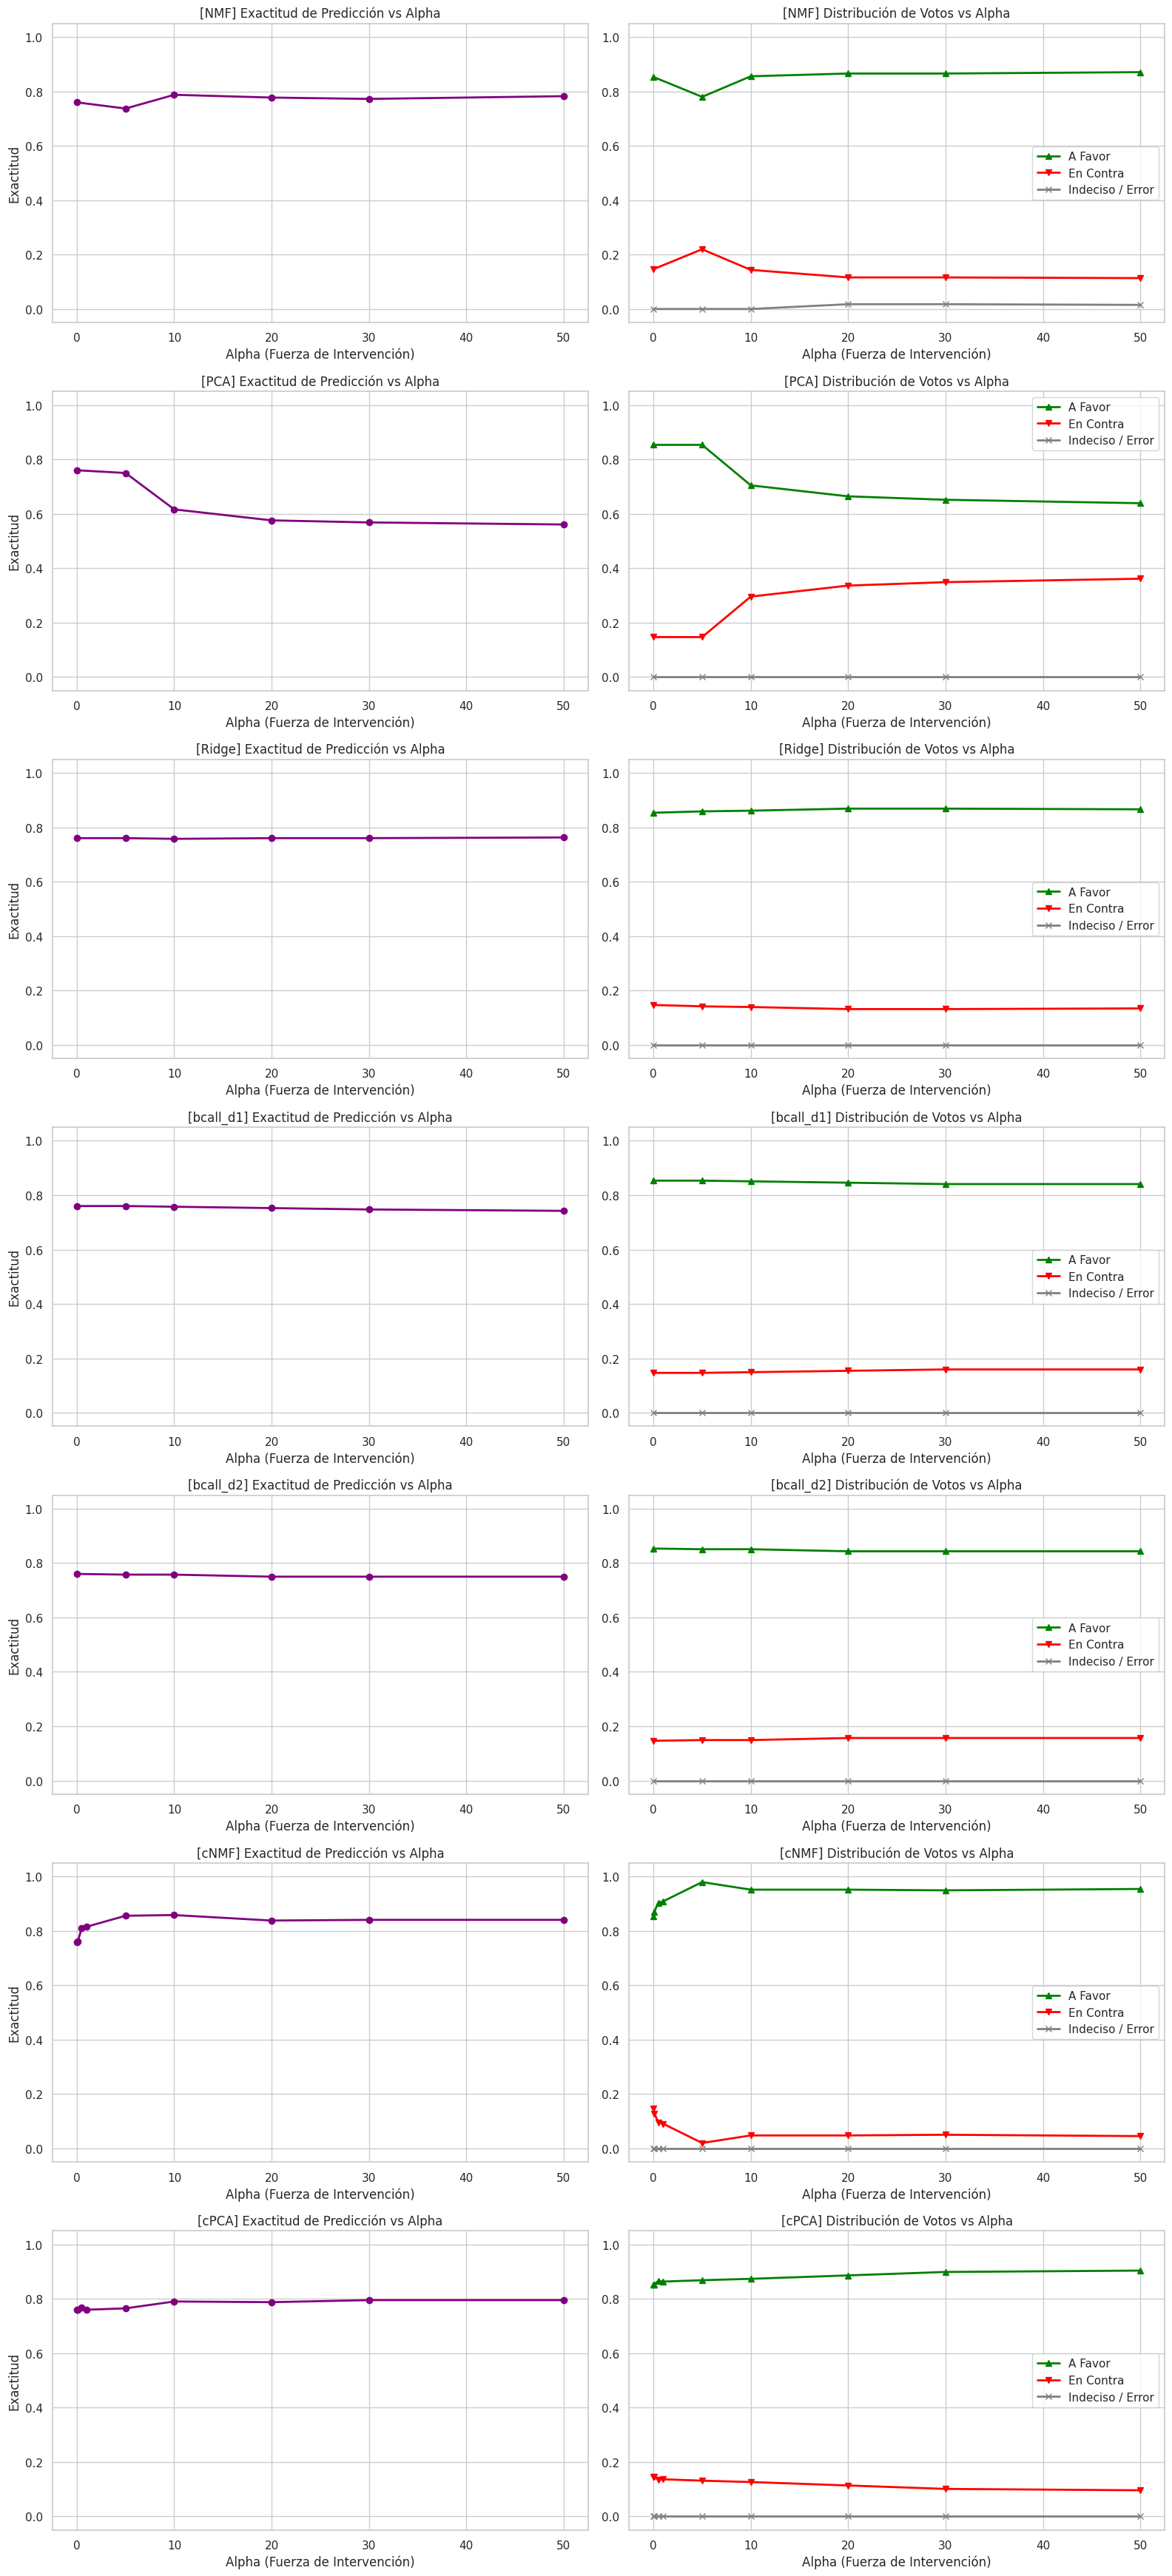

In [4]:
analyze_steering_results('google_gemma-4-E4B-it')

## 3. Análisis Cross-Cultural (Generalización Múltiple)
Métricas de isomorfismo geométrico (PWCCA y Linear CKA) midiendo qué tan similares son las representaciones ideológicas de Llama-3 y Gemma-4 entre el espectro político Chileno y el Estadounidense.


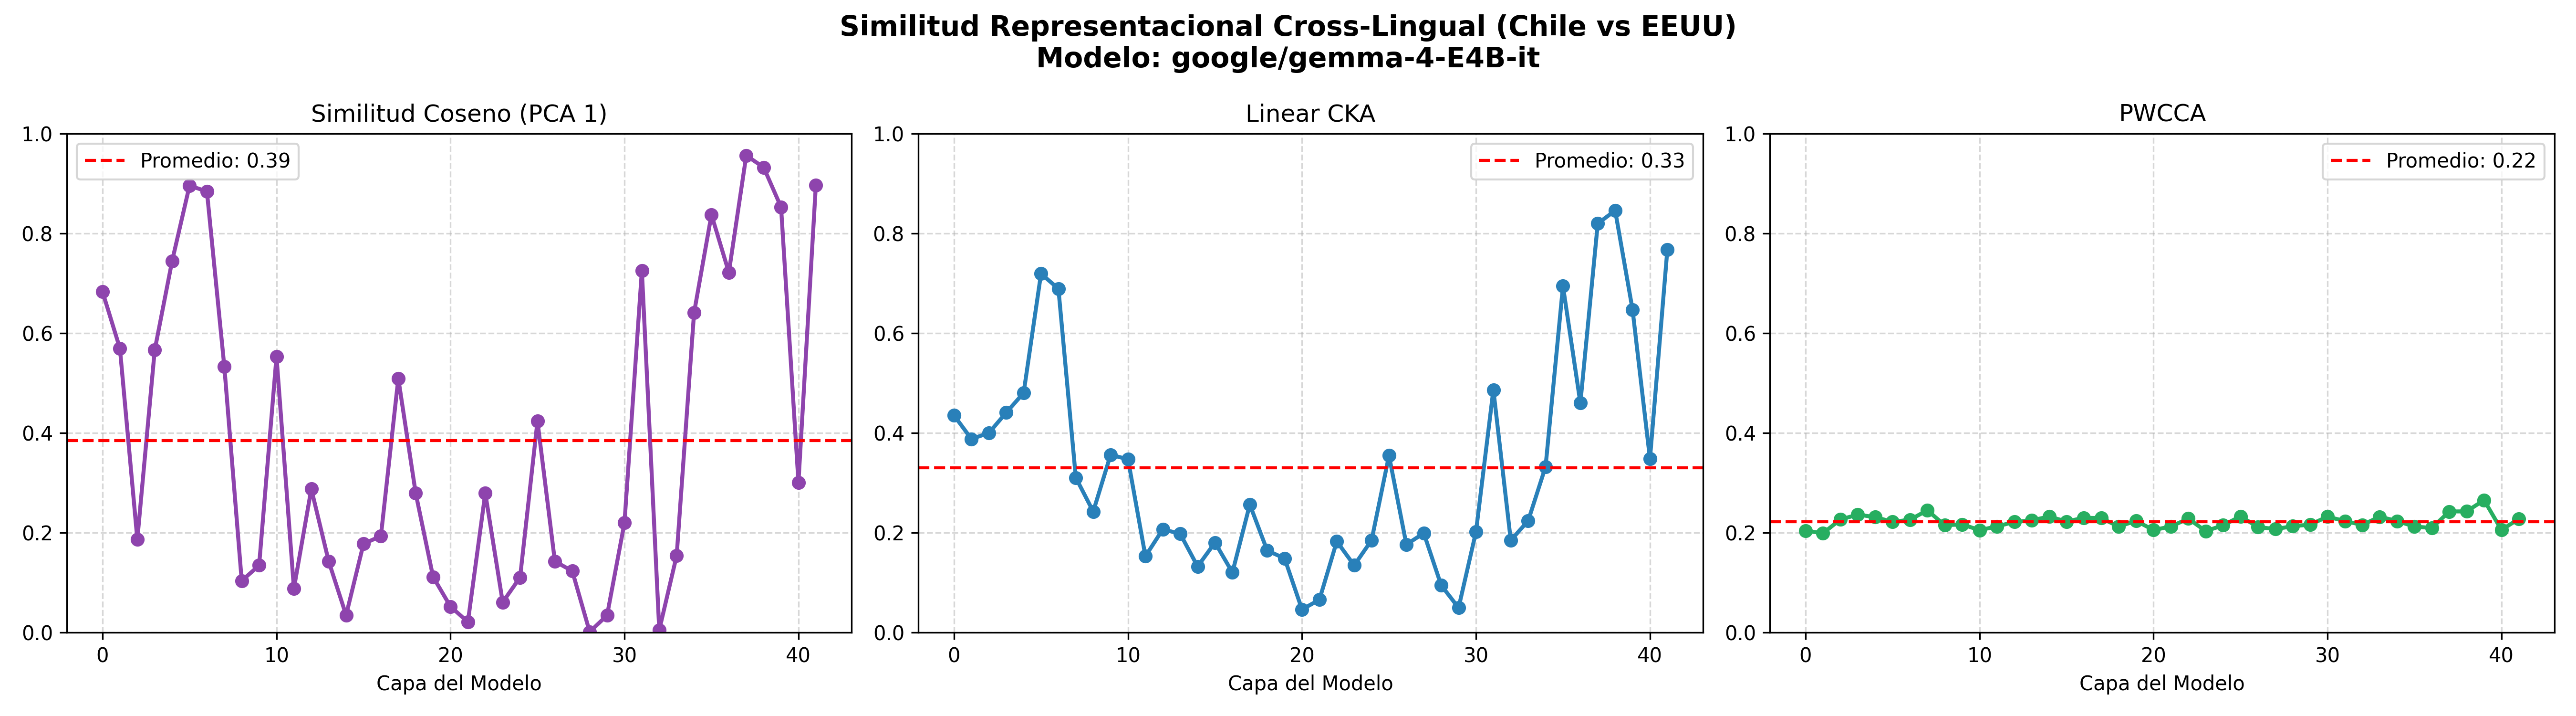

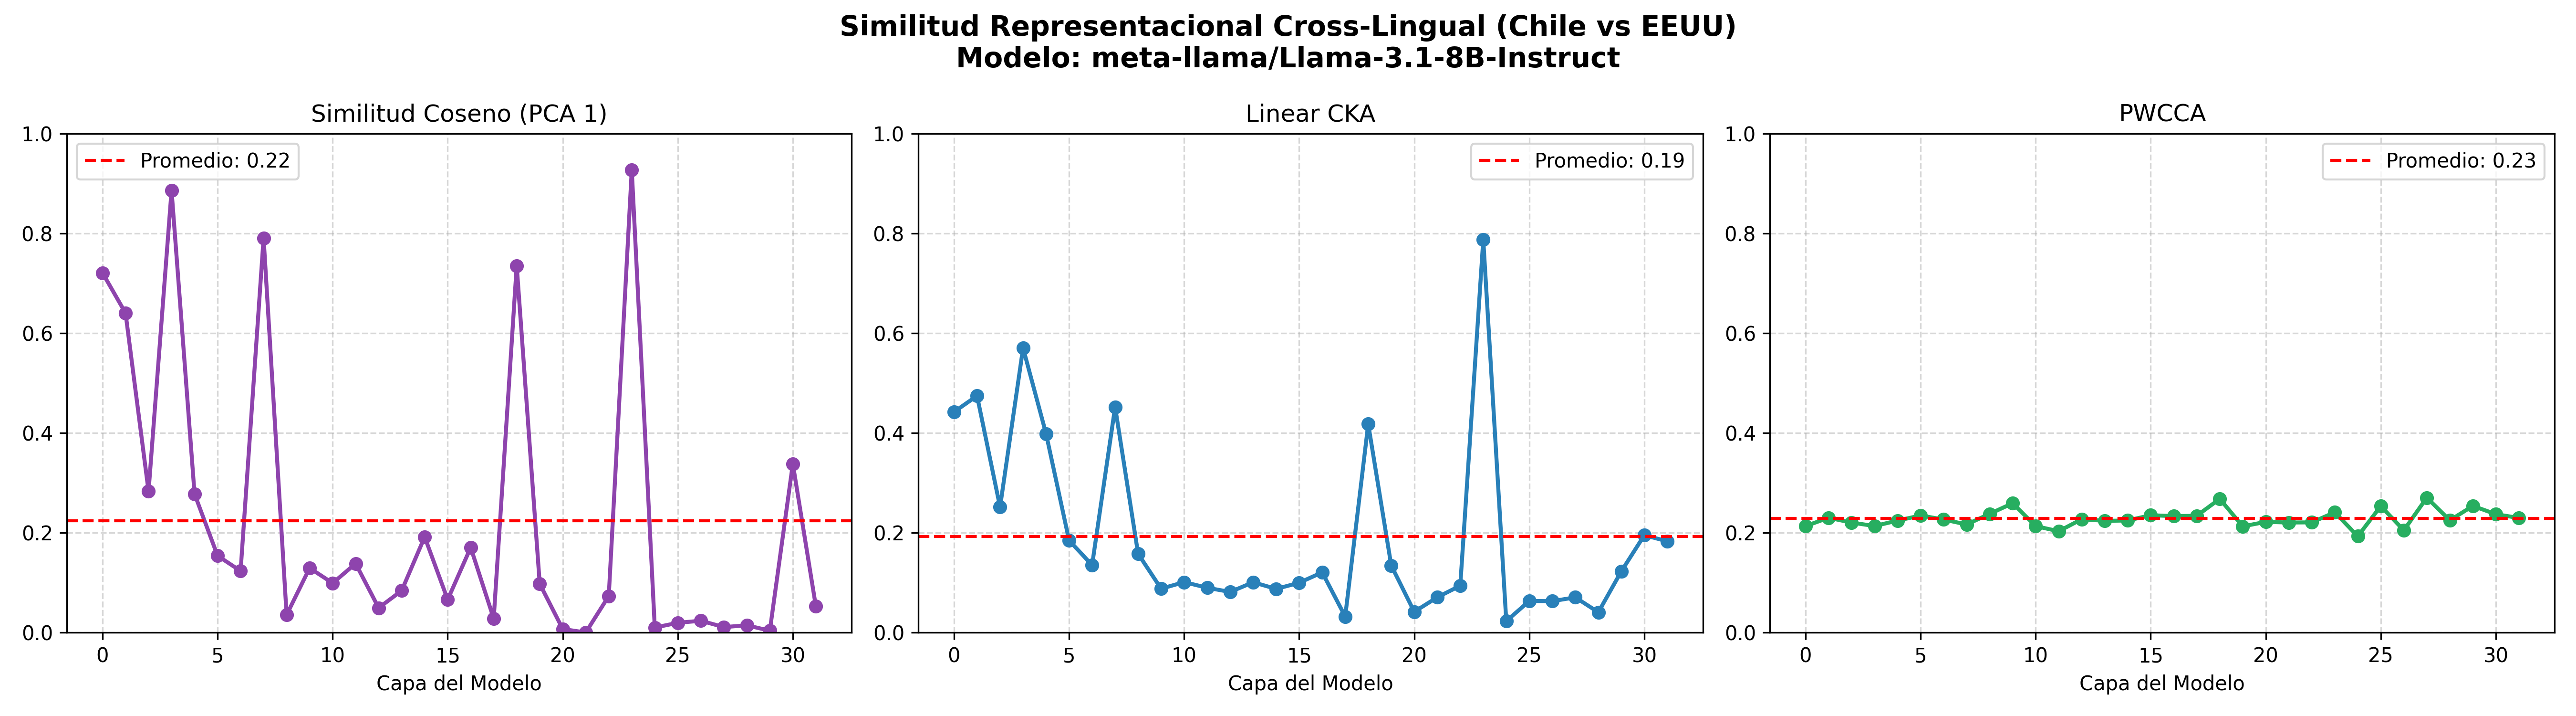

In [5]:

# Mostrar los gráficos generados previamente por el script
crosslingual_dir = FIGURES_DIR / 'crosslingual_analysis'
if crosslingual_dir.exists():
    for img_path in sorted(crosslingual_dir.glob('*.png')):
        display(Image(filename=str(img_path)))
else:
    print("No se encontraron gráficos en figures/crosslingual_analysis/")



## 4. Resultados de Predicción de Votos (Modelos Pequeños)

En esta sección se analizan los resultados de predecir votos de diputados para distintos métodos de steering en modelos de lenguaje de hasta 9B de parámetros. Se incluye la comparación de **cPCA** y **cNMF** contra el método base **Ridge**.

### Análisis General

- **Desempeño de cPCA y cNMF frente a Ridge**: 
  - **Gemma-4-E4B-it** es el modelo que presenta el mejor desempeño en general. Además, **cNMF** (78.79%) logra mejorar levemente a **Ridge** (76.26%).
  - Para **Llama-3.1-8B-Instruct**, el desempeño es moderado (62% - 68%). Aquí, **Ridge** (68.59%) supera por poco a cPCA y cNMF (65.71%).
  - **Qwen3.5-9B** presenta dificultades importantes para esta tarea, con *accuracies* muy bajos en todos los métodos.
- **Conclusión**: Los métodos de factorización cPCA y cNMF funcionan de manera competitiva frente a Ridge. Específicamente cNMF parece capturar mejor la dirección semántica en modelos como Gemma, logrando el mejor accuracy global.


In [16]:
df = pd.read_parquet('../results/voting_predictions/voting_predictions_google_gemma-4-E4B-it_nmf.parquet')
df.head()

,mp_uid,nombre,partido,ley,voto_real,alpha,voto_predicho,respuesta_completa,acierto
0,2,Sergio Bobadilla Muñoz,UDI,Modifica textos legales que indica para fortal...,A FAVOR,0,A FAVOR,VOTO: A FAVOR\nJUSTIFICACIÓN: Como defensor de...,True
1,2,Sergio Bobadilla Muñoz,UDI,Modifica textos legales que indica para fortal...,A FAVOR,5,A FAVOR,VOTO: A FAVOR\nJUSTIFICACIÓN: Porque es fundam...,True
2,2,Sergio Bobadilla Muñoz,UDI,Modifica textos legales que indica para fortal...,A FAVOR,10,A FAVOR,VOTO: A FAVOR\nJUSTIFICACIÓN: Como UDI siempre...,True
3,2,Sergio Bobadilla Muñoz,UDI,Modifica textos legales que indica para fortal...,A FAVOR,20,A FAVOR,VOTO: A FAVOR\nJUSTIFICACIÓN: Como UDI siempre...,True
4,2,Sergio Bobadilla Muñoz,UDI,Modifica textos legales que indica para fortal...,A FAVOR,30,A FAVOR,"VOTO: A FAVOR\nJUSTIFICACIÓN: Como UDI, siempr...",True


In [15]:
pd.DataFrame({"Voto Real":df.voto_real.value_counts(normalize=True), "Voto Predicho": df.voto_predicho.value_counts(normalize=True)})

,Voto Real,Voto Predicho
A FAVOR,0.861111,0.848906
EN CONTRA,0.138889,0.142677
INDECISO,NaN,0.008418


method,Baseline (α=0),NMF,PCA,Ridge,bcall_d1,bcall_d2,cNMF,cPCA
model,,,,,,,,
Qwen_Qwen3.5-9B,0.00%,0.00% (α=0.0),0.00% (α=0.0),10.86% (α=20.0),17.17% (α=10.0),18.69% (α=30.0),1.01% (α=0.1),14.39% (α=1.0)
google_gemma-4-E4B-it,76.01%,78.79% (α=10.0),76.01% (α=0.0),76.26% (α=50.0),76.01% (α=0.0),76.01% (α=0.0),85.86% (α=10.0),79.55% (α=30.0)
meta-llama_Llama-3.1-8B-Instruct,64.12%,65.71% (α=0.0),65.71% (α=0.0),68.59% (α=50.0),62.37% (α=10.0),66.99% (α=50.0),62.12% (α=0.0),70.96% (α=5.0)


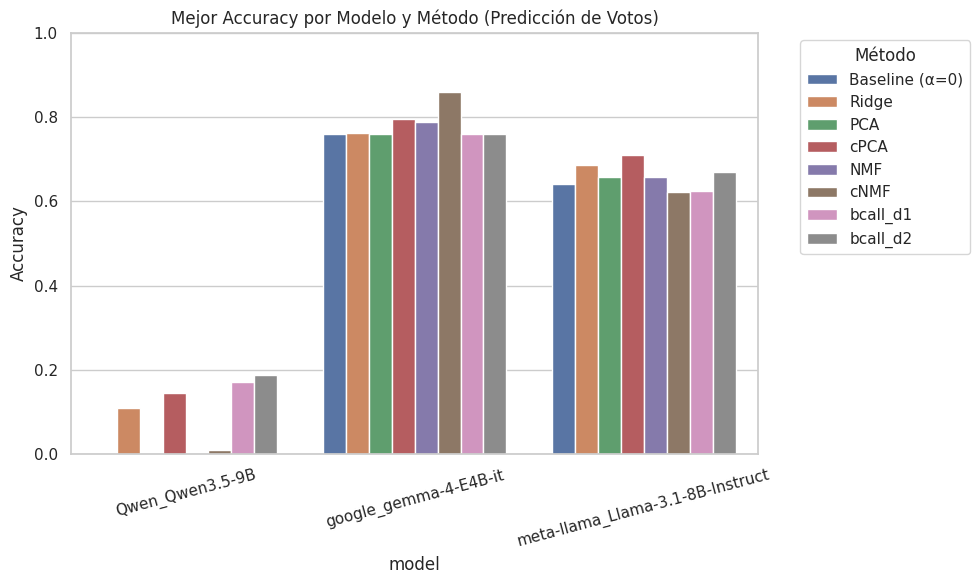

In [6]:
import pandas as pd
from pathlib import Path
from IPython.display import display, HTML
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar resultados
results_dir = Path('../results/voting_predictions')
files = list(results_dir.glob("*.parquet"))

dfs = []
for f in files:
    df = pd.read_parquet(f)
    parts = f.name.replace("voting_predictions_", "").replace(".parquet", "").split("_")
    model = parts[0] + "_" + parts[1]
    method = "_".join(parts[2:])
    
    if method == 'pca': method = 'PCA'
    if method == 'cpca': method = 'cPCA'
    if method == 'nmf': method = 'NMF'
    if method == 'cnmf': method = 'cNMF'
    if method == 'ridge': method = 'Ridge'
    
    df['model'] = model
    df['method'] = method
    dfs.append(df)

all_results = pd.concat(dfs, ignore_index=True)

# Calcular accuracy por modelo, método y alpha
accuracy_df = all_results.groupby(['model', 'method', 'alpha'])['acierto'].mean().reset_index()

# Baseline: accuracy para alpha=0
# El baseline es independiente del método, ya que alpha=0 no usa el vector de steering.
baseline_df = accuracy_df[accuracy_df['alpha'] == 0].groupby('model')['acierto'].mean().reset_index()
baseline_df['method'] = 'Baseline (α=0)'
baseline_df['alpha'] = 0

# Encontrar el mejor alpha para cada modelo y método (incluyendo baseline que sólo tiene alpha=0)
best_idx = accuracy_df.groupby(['model', 'method'])['acierto'].idxmax()
best_results = accuracy_df.loc[best_idx].copy()

# Combinar con baseline
best_results = pd.concat([best_results, baseline_df], ignore_index=True)
best_results.rename(columns={'acierto': 'best_accuracy'}, inplace=True)

def format_accuracy_alpha(row):
    acc = row['best_accuracy']
    alpha = row['alpha']
    if row['method'] == 'Baseline (α=0)':
        return f"{acc:.2%}"
    return f"{acc:.2%} <span style='font-size: 0.8em; color: gray;'>(α={alpha})</span>"

best_results['Accuracy (Best Alpha)'] = best_results.apply(format_accuracy_alpha, axis=1)

# Mostrar Tabla
pivot_table = best_results.pivot(index='model', columns='method', values='Accuracy (Best Alpha)')
display(HTML("<h3>Mejor Accuracy por Modelo y Método (Mejor Alpha en gris)</h3>"))
display(HTML(pivot_table.to_html(escape=False)))

# Graficar
plt.figure(figsize=(10, 6))
# Orden de métodos para que el baseline quede a la izquierda
order = ['Baseline (α=0)', 'Ridge', 'PCA', 'cPCA', 'NMF', 'cNMF', 'bcall_d1', 'bcall_d2']
methods_present = [m for m in order if m in best_results['method'].unique()]

sns.barplot(data=best_results, x='model', y='best_accuracy', hue='method', hue_order=methods_present)
plt.title('Mejor Accuracy por Modelo y Método (Predicción de Votos)')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title='Método', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
